# UNSW-NB15 Binary Classification EDA

This notebook explores the supplied UNSW-NB15 training and testing files for **binary normal-versus-attack classification**. The target is `label` (`0` = normal, `1` = attack). The multiclass `attack_cat` field is not analyzed and must not be used as a model feature. The original CSV files are read-only inputs; figures and the summary are saved under `reports/`.

Run from the project virtual environment. Paths are resolved relative to this notebook, so the project can be moved.

In [50]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data'
FIGURE_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / 'UNSW_NB15_training-set.csv'
TEST_PATH = DATA_DIR / 'UNSW_NB15_testing-set.csv'
train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)
print("Train Shape:",train.shape)
print("Test Shape:",test.shape)
display(train.head())

Train Shape: (175341, 45)
Test Shape: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


## Structure and data quality

The files contain an `id` identifier, traffic predictors, `attack_cat` (unused in this binary task), and `label` (the binary target). Exclude `id`, `label`, and `attack_cat` from the model inputs. The checks below compare data quality and train/test schema.
Duplicate detection drops `id` first, so identical records with different row identifiers are counted as duplicates.

In [51]:
def quality_summary(frame, name):
    numeric = frame.select_dtypes(include=np.number)
    without_id = frame.drop(columns=['id'], errors='ignore')
    return pd.Series({
        'rows': len(frame), 'columns': frame.shape[1],
        'duplicate rows (excluding id)': int(without_id.duplicated().sum()),
        'missing cells': int(frame.isna().sum().sum()),
        'infinite numeric cells': int(np.isinf(numeric).sum().sum()),
        'numeric columns': len(numeric.columns),
        'categorical columns': frame.shape[1] - len(numeric.columns),
    }, name=name)

display(pd.concat([quality_summary(train, 'train'), quality_summary(test, 'test')], axis=1))
schema = pd.DataFrame({'train_dtype': train.dtypes.astype(str), 'test_dtype': test.dtypes.astype(str)})
schema['same_dtype'] = schema.train_dtype == schema.test_dtype
display(schema[~schema.same_dtype] if (~schema.same_dtype).any() else schema.head(0))
print('Train-only columns:', sorted(set(train.columns) - set(test.columns)))
print('Test-only columns:', sorted(set(test.columns) - set(train.columns)))
display(train.dtypes.astype(str).rename('dtype').to_frame())

,train,test
rows,175341,82332
columns,45,45
duplicate rows (excluding id),67601,26387
missing cells,0,0
infinite numeric cells,0,0
numeric columns,41,41
categorical columns,4,4


,train_dtype,test_dtype,same_dtype


Train-only columns: []
Test-only columns: []


,dtype
id,int64
dur,float64
proto,str
service,str
state,str
spkts,int64
dpkts,int64
sbytes,int64
dbytes,int64
rate,float64


## Binary target distribution

`label` is the only target analyzed here: `0` means normal traffic and `1` means attack traffic. Compare the class proportions in both provided splits. Evaluate attack precision and recall, F1, and the confusion matrix in addition to accuracy.

Training set


,count,percent
label,,
Normal (0),56000,31.94
Attack (1),119341,68.06


Testing set


,count,percent
label,,
Normal (0),37000,44.94
Attack (1),45332,55.06


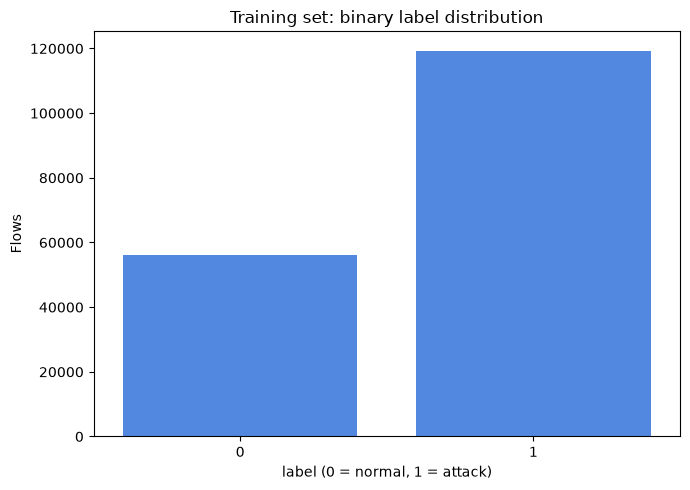

In [52]:
def binary_target_table(frame):
    counts = frame['label'].value_counts(dropna=False).sort_index()
    table = pd.DataFrame({'count': counts, 'percent': (counts / len(frame) * 100).round(2)})
    table.index = table.index.map({0: 'Normal (0)', 1: 'Attack (1)'})
    return table

print('Training set')
display(binary_target_table(train))
print('Testing set')
display(binary_target_table(test))

counts = train['label'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax, color='#3B82F6')
ax.set(title='Training set: binary label distribution', xlabel='label (0 = normal, 1 = attack)', ylabel='Flows')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'target_distributions.png', dpi=160, bbox_inches='tight')
plt.show()

## Categorical feature composition

Protocol, service, and connection state are useful categorical fields. Compare them across attack and benign traffic, while remembering that the plot shows association rather than causation.


proto: top values


,count
proto,
tcp,79946
udp,63283
unas,12084
arp,2859
ospf,2595
sctp,1150
any,300
gre,225
sun-nd,201


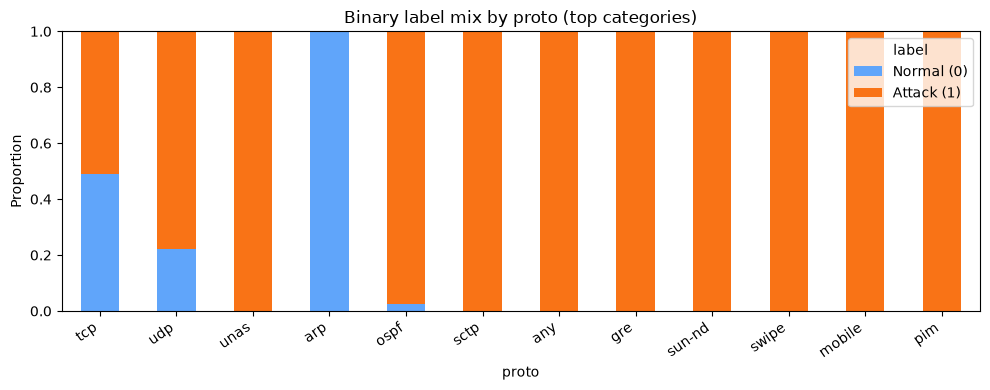


service: top values


,count
service,
-,94168
dns,47294
http,18724
smtp,5058
ftp-data,3995
ftp,3428
ssh,1302
pop3,1105
dhcp,94


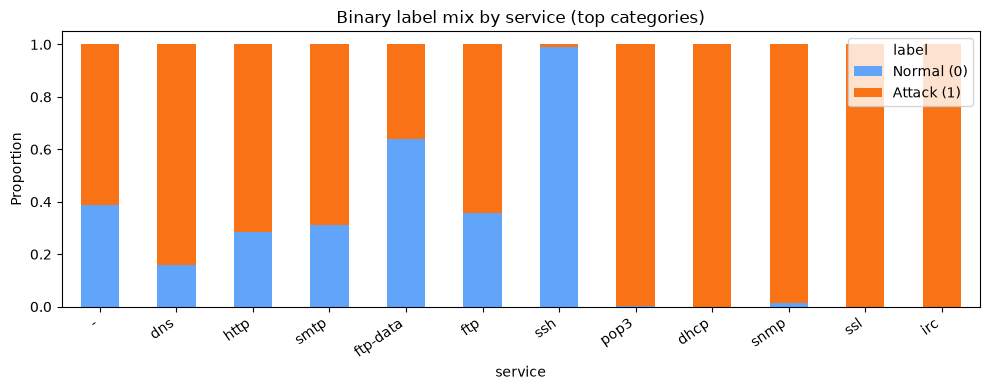


state: top values


,count
state,
INT,82275
FIN,77825
CON,13152
REQ,1991
RST,83
ECO,12
PAR,1
URN,1
no,1


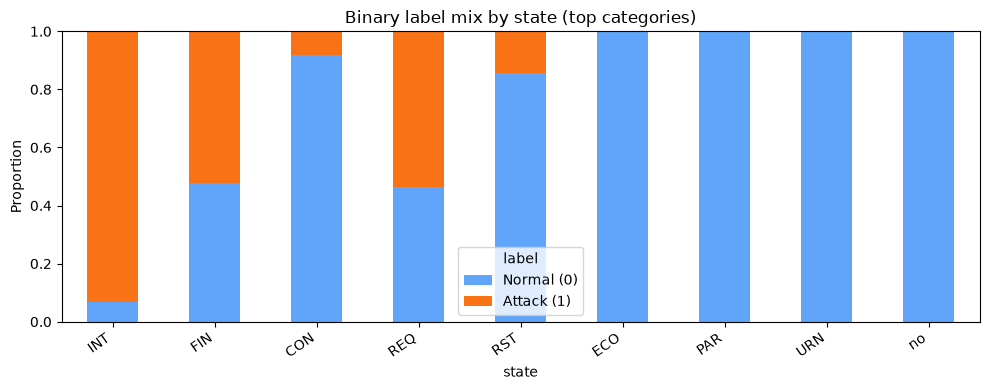

In [53]:
categorical_features = [c for c in ['proto', 'service', 'state'] if c in train.columns]
for col in categorical_features:
    print(f'\n{col}: top values')
    display(train[col].fillna('<missing>').value_counts().head(12).to_frame('count'))
    cross = pd.crosstab(train[col].fillna('<missing>'), train['label'], normalize='index')
    cross = cross.loc[train[col].value_counts().head(12).index.intersection(cross.index)]
    ax = cross.plot(kind='bar', stacked=True, figsize=(10, 4), color=['#60A5FA', '#F97316'])
    ax.set_title(f'Binary label mix by {col} (top categories)')
    ax.set_ylabel('Proportion')
    ax.set_xlabel(col)
    ax.legend(title='label', labels=['Normal (0)', 'Attack (1)'])
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f'{col}_by_label.png', dpi=160, bbox_inches='tight')
    plt.show()

## Numeric feature distributions

Traffic counts and durations commonly have long tails. These plots use a log-scaled count axis where helpful; the data itself is not log-transformed. Inspect extreme values before choosing scaling or robust preprocessing for the eventual model.

,count,mean,std,min,1%,25%,50%,75%,99%,max
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000,0.000008,0.001582,6.680690e-01,4.535333e+01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,1.000,2.000000,2.000000,1.200000e+01,2.340000e+02,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000,0.000000,2.000000,1.000000e+01,4.000000e+02,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,46.000,114.000000,430.000000,1.418000e+03,7.412540e+04,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000,0.000000,164.000000,1.102000e+03,4.743678e+05,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,0.000,32.786140,3225.806520,1.250000e+05,1.000000e+06,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,0.000,62.000000,254.000000,2.540000e+02,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000,0.000000,29.000000,2.520000e+02,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,0.000,13053.338870,879674.750000,8.888889e+07,8.000000e+08,5.988000e+09
dload,175341.0,6.712056e+05,2.421312e+06,0.0,0.000,0.000000,1447.022705,2.784487e+04,1.465589e+07,2.242273e+07


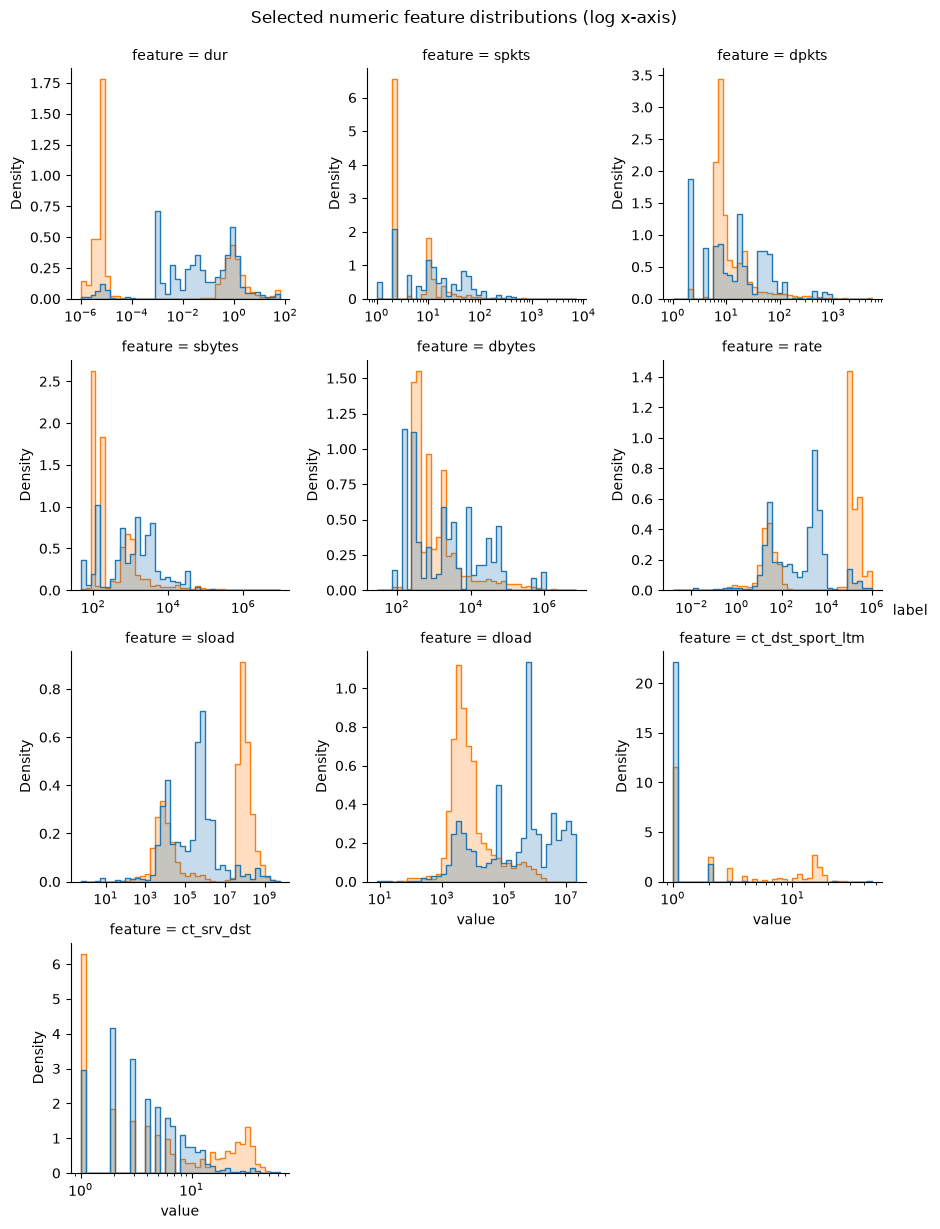

In [54]:
numeric = train.select_dtypes(include=np.number).drop(columns=['id', 'label'], errors='ignore')
display(numeric.describe(percentiles=[.01, .25, .5, .75, .99]).T)

# Plot a representative subset of numeric traffic features for readability.
candidate = [c for c in ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'ct_dst_sport_ltm', 'ct_srv_dst'] if c in numeric.columns]
if candidate:
    sample = train.groupby('label', group_keys=False).sample(n=min(10_000, train['label'].value_counts().min()), random_state=42)
    plot_data = sample[candidate + ['label']].replace([np.inf, -np.inf], np.nan).melt(id_vars='label', var_name='feature', value_name='value').dropna()
    g = sns.FacetGrid(plot_data, col='feature', col_wrap=3, sharex=False, sharey=False, height=3)
    g.map_dataframe(sns.histplot, x='value', hue='label', bins=40, element='step', stat='density', common_norm=False, log_scale=(True, False))
    g.add_legend(title='label')
    g.fig.suptitle('Selected numeric feature distributions (log x-axis)', y=1.02)
    g.savefig(FIGURE_DIR / 'numeric_feature_distributions.png', dpi=160, bbox_inches='tight')
    plt.show()

## Correlations and train/test identifier check

Highly correlated numeric features can be redundant. Correlation is only a linear association check; identifiers and targets are excluded from the heatmap. In these provided files, `id` counts restart at 1 in the test split, so matching ID values across files do not mean the same flow appears in both.

Train id range: 1–175,341
Test id range: 1–82,332
IDs are row counters that restart in each file; exclude id from model features.
Test rows exactly matching a training row after dropping id: 4,247


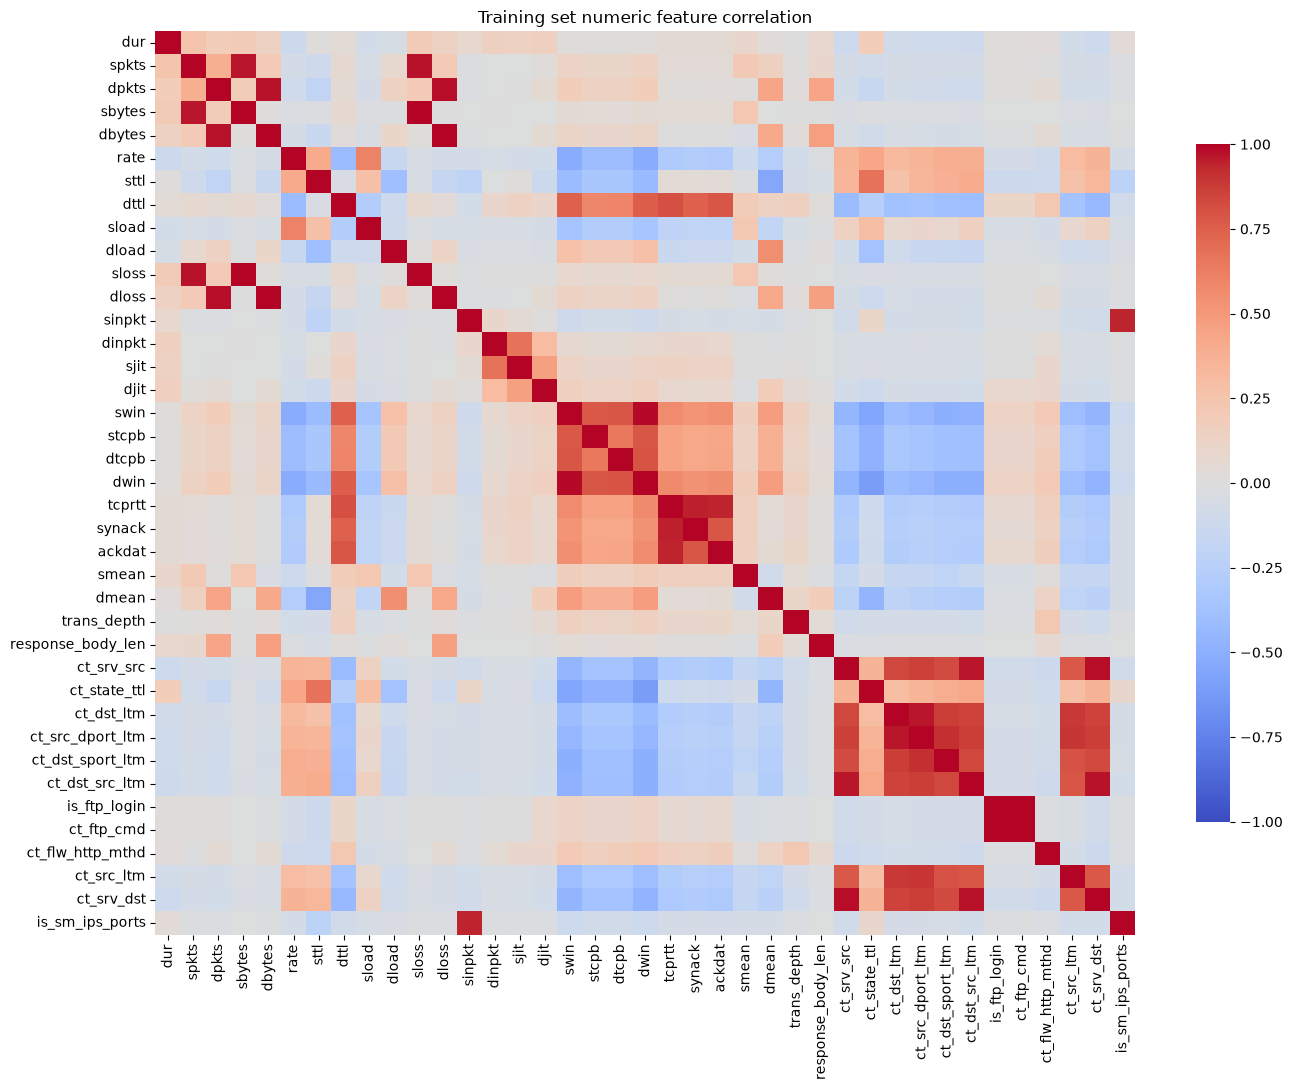

,feature_1,feature_2,correlation,abs_correlation
1321,is_ftp_login,ct_ftp_cmd,1.000000,1.000000
167,dbytes,dloss,0.996504,0.996504
127,sbytes,sloss,0.996109,0.996109
643,swin,dwin,0.990140,0.990140
1090,ct_srv_src,ct_srv_dst,0.980323,0.980323
89,dpkts,dloss,0.978636,0.978636
1285,ct_dst_src_ltm,ct_srv_dst,0.972370,0.972370
82,dpkts,dbytes,0.971907,0.971907
49,spkts,sloss,0.971069,0.971069
1085,ct_srv_src,ct_dst_src_ltm,0.967138,0.967138


In [55]:
if 'id' in train.columns and 'id' in test.columns:
    print(f"Train id range: {train['id'].min():,}–{train['id'].max():,}")
    print(f"Test id range: {test['id'].min():,}–{test['id'].max():,}")
    print('IDs are row counters that restart in each file; exclude id from model features.')

train_without_id = train.drop(columns=['id'], errors='ignore')
test_without_id = test.drop(columns=['id'], errors='ignore')
train_hashes = set(pd.util.hash_pandas_object(train_without_id, index=False))
shared_rows = int(pd.util.hash_pandas_object(test_without_id, index=False).isin(train_hashes).sum())
print(f'Test rows exactly matching a training row after dropping id: {shared_rows:,}')

corr = numeric.corr(numeric_only=True)
if not corr.empty:
    plt.figure(figsize=(14, 11))
    sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=0, cbar_kws={'shrink': .75})
    plt.title('Training set numeric feature correlation')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'numeric_correlation_heatmap.png', dpi=160, bbox_inches='tight')
    plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename('correlation').reset_index()
pairs.columns = ['feature_1', 'feature_2', 'correlation']
display(pairs.assign(abs_correlation=pairs.correlation.abs()).sort_values('abs_correlation', ascending=False).head(15))

## Binary modeling implications

- Use `label` as the target: 0 = normal and 1 = attack.
- Exclude `id`, `label`, and the unused `attack_cat` field from model features.
- Keep the provided training and testing files separate for final evaluation.
- Evaluate attack precision, attack recall, F1, and the confusion matrix alongside accuracy.
- Fit imputers, encoders, scaling, feature selection, and any resampling on training data only, ideally inside a scikit-learn pipeline.
- Duplicate checks ignore `id`; cross-split exact-row matches are counted after dropping `id` and may make test metrics optimistic.

Figures are saved to `reports/figures/` for reuse in the project report.